# Rozwiązanie prowadzącego. Agent uczący się przejścia labiryntu

**Cel:** nauczyć agenta dotarcia do wyjścia na jednej planszy 5 × 5 i porównać
zamrożoną strategię z agentem losowym. Stosujemy tablicowy Q-learning.
Notebook zawiera pełny kod i działa samodzielnie w Jupyterze lub Google Colab.
Uruchom komórki od góry do dołu przez **Run all / Uruchom wszystkie**.

Przebieg odpowiada warsztatowi: środowisko i agent losowy (0–10 min), wybór akcji
(10–25 min), uczenie (25–55 min), ocena (55–75 min), ścieżki i wnioski (75–90 min).
Na końcu jest porównanie epsilon 0,05 i 0,3 oraz zapis wyników do plików.

Nie jest potrzebny GPU, silnik gry ani Pandas. Wystarczą NumPy, Matplotlib i Jupyter.
Współrzędne zapisujemy jako **(wiersz, kolumna)** od zera. Wiersz rośnie w dół.

In [1]:
from pathlib import Path
import csv
import json
import platform
from IPython.display import Markdown, display

get_ipython().run_line_magic("matplotlib", "inline")

## 1. Konfiguracja

Wartości Q zaczynają od zera. Każdy wariant uczy się przez 300 epizodów.
Epsilon jest stałe podczas treningu, bez stopniowego zmniejszania.
Osobne ziarna losowania sterują startami, akcjami podczas treningu i oceną.
Lista 20 startów testowych zawiera każde wolne pole poza celem dokładnie raz.

In [2]:
from collections import deque
from dataclasses import dataclass

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


SIZE = 5
WALLS = frozenset({(0, 1), (1, 1), (3, 1), (3, 3)})
GOAL = (4, 4)
GRID = np.zeros((SIZE, SIZE), dtype=int)
for _wall in WALLS:
    GRID[_wall] = 1

# Współrzędne mają postać (wiersz, kolumna); wiersz rośnie w dół.
ACTIONS = ((-1, 0), (0, 1), (1, 0), (0, -1))
ACTION_NAMES = ("góra", "prawo", "dół", "lewo")
ACTION_ARROWS = ("↑", "→", "↓", "←")

# Stała lista obejmuje każde wolne pole poza celem dokładnie raz.
TEST_STARTS = (
    (0, 0), (0, 2), (0, 3), (0, 4),
    (1, 0), (1, 2), (1, 3), (1, 4),
    (2, 0), (2, 1), (2, 2), (2, 3), (2, 4),
    (3, 0), (3, 2), (3, 4),
    (4, 0), (4, 1), (4, 2), (4, 3),
)

In [3]:
CONFIG = {
    "episodes": 300,
    "alpha": 0.1,
    "gamma": 0.95,
    "max_steps": 50,
    "epsilon": 0.2,
    "epsilons": [0.05, 0.2, 0.3],
    "start_seed": 2026,
    "action_seed": 2027,
    "eval_seed": 2028,
}

print(json.dumps(CONFIG, ensure_ascii=False, indent=2))
print("Ściany:", sorted(WALLS), "| Cel:", GOAL)
print("Starty testowe:", TEST_STARTS)
print("Python", platform.python_version(), "| NumPy", np.__version__)

{
  "episodes": 300,
  "alpha": 0.1,
  "gamma": 0.95,
  "max_steps": 50,
  "epsilon": 0.2,
  "epsilons": [
    0.05,
    0.2,
    0.3
  ],
  "start_seed": 2026,
  "action_seed": 2027,
  "eval_seed": 2028
}
Ściany: [(0, 1), (1, 1), (3, 1), (3, 3)] | Cel: (4, 4)
Starty testowe: ((0, 0), (0, 2), (0, 3), (0, 4), (1, 0), (1, 2), (1, 3), (1, 4), (2, 0), (2, 1), (2, 2), (2, 3), (2, 4), (3, 0), (3, 2), (3, 4), (4, 0), (4, 1), (4, 2), (4, 3))
Python 3.12.14 | NumPy 2.3.5


## 2. Środowisko i osiągalność celu

Stanem jest pozycja agenta. Akcje 0–3 oznaczają kolejno górę, prawo, dół i lewo.
Każda próba ruchu dostaje dokładnie jedną nagrodę:

| Zdarzenie | Nagroda | Nowa pozycja |
|---|---:|---|
| Wejście na cel | +10 | Cel, koniec epizodu |
| Zwykły dozwolony ruch | −0,1 | Sąsiednie pole |
| Ściana albo wyjście poza planszę | −1 | Ta sama pozycja |

`step()` sygnalizuje wyłącznie rzeczywiste zakończenie na celu. Limit 50 kroków
obsługuje pętla epizodu. Funkcja BFS poniżej sprawdza osiągalność i daje długość
najkrótszej drogi do porównania. Agent nie korzysta z BFS przy wyborze akcji.

In [4]:
class MazeEnv:
    """Deterministyczne środowisko; limit kroków obsługuje run_episode."""

    def __init__(self):
        self.position = None

    def reset(self, start=None, rng=None):
        """Ustaw start, a przy braku startu wylosuj wolne pole poza celem."""
        if start is None:
            if rng is None:
                raise ValueError("Losowy start wymaga generatora rng.")
            start = TEST_STARTS[int(rng.integers(len(TEST_STARTS)))]
        start = tuple(start)
        if start not in TEST_STARTS:
            raise ValueError("Start musi być wolnym polem innym niż cel.")
        self.position = start
        return self.position

    def step(self, action):
        """Zwróć (nowy_stan, nagroda, osiągnięto_cel)."""
        if self.position is None:
            raise RuntimeError("Przed ruchem wywołaj reset().")
        if self.position == GOAL:
            raise RuntimeError("Epizod zakończył się. Wywołaj reset().")
        if action not in range(len(ACTIONS)):
            raise ValueError("Akcja musi być liczbą 0, 1, 2 lub 3.")
        dr, dc = ACTIONS[action]
        r, c = self.position
        candidate = (r + dr, c + dc)

        # Nagrody są rozłączne: każdy ruch otrzymuje dokładnie jedną.
        if not (0 <= candidate[0] < SIZE and 0 <= candidate[1] < SIZE):
            return self.position, -1.0, False
        if candidate in WALLS:
            return self.position, -1.0, False
        self.position = candidate
        if candidate == GOAL:
            return candidate, 10.0, True
        return candidate, -0.1, False


def shortest_steps(start):
    """Liczba ruchów najkrótszej drogi wyznaczona BFS, bez udziału Q."""
    start = tuple(start)
    if start == GOAL:
        return 0
    if start not in TEST_STARTS:
        raise ValueError("Nieprawidłowy start.")
    queue = deque([(start, 0)])
    visited = {start}
    while queue:
        (r, c), distance = queue.popleft()
        for dr, dc in ACTIONS:
            candidate = (r + dr, c + dc)
            if not (0 <= candidate[0] < SIZE and 0 <= candidate[1] < SIZE):
                continue
            if candidate in WALLS or candidate in visited:
                continue
            if candidate == GOAL:
                return distance + 1
            visited.add(candidate)
            queue.append((candidate, distance + 1))
    raise ValueError("Cel nie jest osiągalny z tego startu.")

In [5]:
def plot_maze(path=None, q=None, ax=None, title="Labirynt 5 × 5"):
    """Narysuj ściany, cel, ścieżkę i opcjonalnie zachłanne akcje tablicy Q."""
    if ax is None:
        _, ax = plt.subplots(figsize=(5.4, 5.4))
    ax.imshow(GRID, cmap=ListedColormap(["#f1f5f9", "#334155"]),
              vmin=0, vmax=1, interpolation="nearest")
    ax.scatter(GOAL[1], GOAL[0], s=650, marker="s", c="#a7f3d0", zorder=2)
    ax.text(GOAL[1], GOAL[0], "CEL", ha="center", va="center",
            fontsize=10, fontweight="bold", color="#065f46", zorder=5)
    if q is not None:
        for state in TEST_STARTS:
            values = q[state]
            # Pokazujemy wszystkie remisy, bez dodatkowego losowania.
            arrows = "".join(ACTION_ARROWS[int(i)] for i in
                             np.flatnonzero(values == np.max(values)))
            ax.text(state[1], state[0], arrows, ha="center", va="center",
                    color="#64748b", fontsize=13, zorder=3)
    if path:
        rows, columns = zip(*path)
        ax.plot(columns, rows, "o-", color="#2563eb", markersize=4,
                linewidth=2, alpha=0.9, zorder=4)
        ax.scatter(columns[0], rows[0], s=120, marker="o", c="#f59e0b",
                   edgecolors="white", zorder=6, label="Start")
        ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
    ax.set_xticks(range(SIZE))
    ax.set_yticks(range(SIZE))
    ax.set_xticks(np.arange(-0.5, SIZE, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, SIZE, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=1.5)
    ax.tick_params(which="minor", bottom=False, left=False)
    ax.set_xlabel("Kolumna")
    ax.set_ylabel("Wiersz")
    ax.set_title(title)
    ax.set_aspect("equal")
    return ax.figure, ax


def plot_rewards(histories, window=20):
    """Pokaż nagrodę każdego epizodu i średnią kroczącą bez dopisywania próbek."""
    if not histories or window < 1:
        raise ValueError("Podaj historie oraz dodatnie okno średniej.")
    fig, axes = plt.subplots(len(histories), 1,
                             figsize=(9, 3.0 * len(histories)), squeeze=False)
    for ax, (label, history) in zip(axes[:, 0], histories.items()):
        rewards = np.array([result.total_reward for result in history])
        episodes = np.arange(1, len(rewards) + 1)
        ax.plot(episodes, rewards, color="#93c5fd", linewidth=0.9,
                label="Nagroda epizodu")
        if len(rewards) >= window:
            average = np.convolve(rewards, np.ones(window) / window, mode="valid")
            ax.plot(episodes[window - 1:], average, color="#1d4ed8",
                    linewidth=2, label=f"Średnia z {window} epizodów")
        ax.set_title(label)
        ax.set_xlabel("Epizod")
        ax.set_ylabel("Suma nagród")
        ax.grid(alpha=0.2)
        ax.legend(loc="lower right")
    fig.tight_layout()
    return fig, axes[:, 0]

Cel osiągalny ze wszystkich 20 startów.
Najkrótsze drogi mają od 1 do 8 kroków.


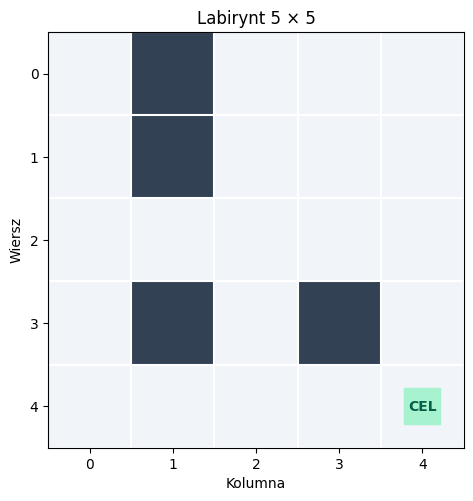

In [6]:
assert len(TEST_STARTS) == 20
assert set(TEST_STARTS) == {
    (r, c) for r in range(SIZE) for c in range(SIZE)
    if (r, c) not in WALLS and (r, c) != GOAL
}
distances = [shortest_steps(start) for start in TEST_STARTS]
print("Cel osiągalny ze wszystkich", len(distances), "startów.")
print("Najkrótsze drogi mają od", min(distances), "do", max(distances), "kroków.")
plot_maze()
plt.show()

### Przejście agenta losowego

Agent losuje każdą z czterech akcji z takim samym prawdopodobieństwem.
Nie wykluczamy ruchów w ściany. Każda próba liczy się jako krok, nawet gdy pozycja
pozostaje bez zmian. Ta demonstracja używa osobnego generatora i nie zmienia testu.

Sukces: True; kroki: 39; suma nagród: -18.1


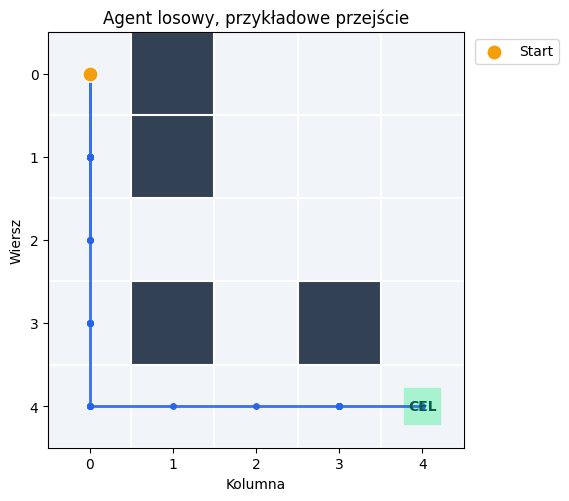

In [7]:
demo_env = MazeEnv()
demo_rng = np.random.default_rng(2030)
demo_state = demo_env.reset(TEST_STARTS[0])
demo_path = [demo_state]
demo_return = 0.0
demo_success = False
for demo_step in range(1, CONFIG["max_steps"] + 1):
    demo_action = int(demo_rng.integers(len(ACTIONS)))
    demo_state, demo_reward, demo_success = demo_env.step(demo_action)
    demo_return += demo_reward
    demo_path.append(demo_state)
    if demo_success:
        break

print(f"Sukces: {demo_success}; kroki: {demo_step}; suma nagród: {demo_return:.1f}")
plot_maze(demo_path, title="Agent losowy, przykładowe przejście")
plt.show()

## 3. Wybór akcji i aktualizacja Q

Tablica ma kształt `(5, 5, 4)`. `Q[r, c, a]` to oszacowana wartość wykonania
akcji `a` w pozycji `(r, c)`, z uwzględnieniem przyszłych nagród.

Wybór epsilon-zachłanny losuje akcję z prawdopodobieństwem epsilon.
W przeciwnym przypadku wybiera akcję o największym Q. Remisy rozstrzygamy losowo,
również wtedy, gdy epsilon wynosi zero.

Aktualizacja jednej wartości ma postać:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,[r + \gamma V(s') - Q(s,a)].$$

Dla osiągniętego celu $V(s')=0$. W pozostałych przejściach
$V(s')=\max_{a'}Q(s',a')$.

**Limit czasu nie oznacza osiągnięcia celu.** Jeśli epizod urwie się po 50 krokach,
ostatnia aktualizacja nadal uwzględnia przyszłe Q. Po osiągnięciu celu przyszłe Q
jest zerowe, także gdy cel osiągnięto dokładnie w kroku 50.

In [8]:
def choose_action(q, state, epsilon, rng):
    """Wybór epsilon-zachłanny; remisy największego Q rozstrzygamy losowo."""
    if not 0.0 <= epsilon <= 1.0:
        raise ValueError("Epsilon musi należeć do [0, 1].")
    if rng.random() < epsilon:
        return int(rng.integers(len(ACTIONS)))
    values = q[state]
    best_actions = np.flatnonzero(values == np.max(values))
    return int(rng.choice(best_actions))


def update_q(q, state, action, reward, next_state, terminated,
             alpha=0.1, gamma=0.95):
    """Zaktualizuj jedną parę stan–akcja; jedynie cel zeruje przyszłe Q."""
    future_value = 0.0 if terminated else float(np.max(q[next_state]))
    target = reward + gamma * future_value
    q[state + (action,)] += alpha * (target - q[state + (action,)])

In [9]:
q_initial = np.zeros((SIZE, SIZE, len(ACTIONS)), dtype=float)
assert q_initial.shape == (5, 5, 4)
print("Q na starcie:", q_initial[TEST_STARTS[0]])

Q na starcie: [0. 0. 0. 0.]


## 4. Pętla uczenia

`run_episode` rozróżnia dwa zakończenia: `terminated` po wejściu na cel oraz
`truncated` po wyczerpaniu limitu kroków. Włączenie `learn=True` pozwala zmieniać Q.
Każde wywołanie `train()` tworzy nową, zerową tablicę.

Starty treningowe losujemy raz, z powtórzeniami. Tę samą listę wykorzystamy
w porównaniu różnych wartości epsilon. Losowanie akcji ma osobny generator,
więc różna długość epizodów nie zmienia przygotowanej listy startów.

In [10]:
@dataclass
class EpisodeResult:
    """Wynik epizodu, wraz ze wszystkimi pozycjami i próbami ruchu."""

    start: tuple
    success: bool
    steps: int
    total_reward: float
    terminated: bool
    truncated: bool
    path: list
    actions: list


def run_episode(env, start, rng, q=None, epsilon=1.0, learn=False,
                alpha=0.1, gamma=0.95, max_steps=50):
    """Uruchom epizod; bez learn=True tablica Q pozostaje bez zmian."""
    if max_steps < 1:
        raise ValueError("Limit kroków musi być dodatni.")
    if learn and q is None:
        raise ValueError("Uczenie wymaga tablicy Q.")
    state = env.reset(start)
    path, actions = [state], []
    total_reward = 0.0
    terminated = False
    for step in range(1, max_steps + 1):
        # q=None oznacza agenta losowego, również losującego ruchy błędne.
        action = (int(rng.integers(len(ACTIONS))) if q is None
                  else choose_action(q, state, epsilon, rng))
        next_state, reward, terminated = env.step(action)
        if learn:
            # Obcięcie na limicie czasu NIE jest stanem końcowym labiryntu.
            # Nawet w ostatnim kroku bootstrappujemy, chyba że osiągnięto cel.
            update_q(q, state, action, reward, next_state, terminated,
                     alpha=alpha, gamma=gamma)
        total_reward += reward
        actions.append(action)
        path.append(next_state)
        state = next_state
        if terminated:
            break
    return EpisodeResult(
        start=tuple(start), success=terminated, steps=step,
        total_reward=float(total_reward), terminated=terminated,
        truncated=not terminated, path=path, actions=actions,
    )


def sample_training_starts(episodes=300, seed=2026):
    """Wylosuj listę startów z osobnego generatora, niezależnego od akcji."""
    if episodes < 1:
        raise ValueError("Liczba epizodów musi być dodatnia.")
    rng = np.random.default_rng(seed)
    return [TEST_STARTS[int(i)]
            for i in rng.integers(len(TEST_STARTS), size=episodes)]


def train(epsilon=0.2, episodes=300, alpha=0.1, gamma=0.95,
          max_steps=50, starts=None, start_seed=2026, action_seed=2027):
    """Ucz od zera; zwróć tablicę Q i wyniki kolejnych epizodów."""
    if not 0.0 <= epsilon <= 1.0:
        raise ValueError("Epsilon musi należeć do [0, 1].")
    if not 0.0 < alpha <= 1.0 or not 0.0 <= gamma <= 1.0:
        raise ValueError("Wymagane: alpha w (0, 1], gamma w [0, 1].")
    if episodes < 1:
        raise ValueError("Liczba epizodów musi być dodatnia.")
    if starts is None:
        starts = sample_training_starts(episodes, start_seed)
    if len(starts) != episodes:
        raise ValueError("Lista startów musi mieć długość równą episodes.")
    q = np.zeros((SIZE, SIZE, len(ACTIONS)), dtype=float)
    rng = np.random.default_rng(action_seed)
    env = MazeEnv()
    history = [run_episode(env, start, rng, q=q, epsilon=epsilon, learn=True,
                           alpha=alpha, gamma=gamma, max_steps=max_steps)
               for start in starts]
    return q, history

Epizody treningowe: 300
Sukcesy w pierwszych 30: 29 / 30
Sukcesy w ostatnich 30: 30 / 30


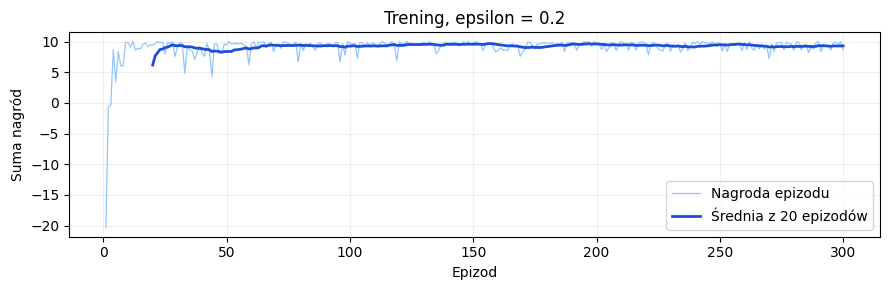

In [11]:
training_starts = sample_training_starts(
    episodes=CONFIG["episodes"], seed=CONFIG["start_seed"]
)
q, history = train(
    epsilon=CONFIG["epsilon"], episodes=CONFIG["episodes"],
    alpha=CONFIG["alpha"], gamma=CONFIG["gamma"],
    max_steps=CONFIG["max_steps"], starts=training_starts,
    start_seed=CONFIG["start_seed"], action_seed=CONFIG["action_seed"],
)
qs = {CONFIG["epsilon"]: q}
histories = {CONFIG["epsilon"]: history}

print("Epizody treningowe:", len(history))
print("Sukcesy w pierwszych 30:", sum(ep.success for ep in history[:30]), "/ 30")
print("Sukcesy w ostatnich 30:", sum(ep.success for ep in history[-30:]), "/ 30")
plot_rewards({"Trening, epsilon = 0.2": history})
plt.show()

Wykres pokazuje sumę nagród z każdego epizodu i średnią z ostatnich 20 epizodów.
Nie oczekujemy monotonicznego wzrostu. Starty mają różną odległość od celu,
a agent wciąż wykonuje losowe ruchy z prawdopodobieństwem 0,2.
Średnia krocząca opisuje trening, nie zastępuje osobnego testu.

## 5. Ocena zamrożonej strategii

Porównujemy agenta losowego i wyuczonego na tej samej, jawnej liście 20 startów.
Dla Q ustawiamy **epsilon=0 i learn=False**. Sprawdzamy też, że ocena nie zmienia
żadnej wartości Q. Ruchy wynikające z remisów Q nadal mogą być losowane.

Skuteczność to liczba sukcesów podzielona przez wszystkie 20 prób.
Niepowodzenie po 50 krokach pozostaje w mianowniku. Średnią i medianę kroków
liczymy osobno, wyłącznie dla udanych prób. Gdy sukcesów nie ma, średnia nie istnieje.

In [12]:
def evaluate(q=None, starts=TEST_STARTS, seed=2028, max_steps=50):
    """Oceń zamrożoną strategię (epsilon=0), a dla q=None agenta losowego."""
    rng = np.random.default_rng(seed)
    env = MazeEnv()
    return [run_episode(env, start, rng, q=q, epsilon=0.0, learn=False,
                        max_steps=max_steps) for start in starts]


def summarize(results):
    """Niepowodzenia liczą się w mianowniku skuteczności; kroki tylko sukcesów."""
    if not results:
        raise ValueError("Ocena wymaga co najmniej jednego epizodu.")
    successful_steps = [result.steps for result in results if result.success]
    successes = len(successful_steps)
    return {
        "episodes": len(results),
        "successes": successes,
        "failures": len(results) - successes,
        "success_rate": successes / len(results),
        "mean_steps_success": (float(np.mean(successful_steps))
                               if successful_steps else None),
        "median_steps_success": (float(np.median(successful_steps))
                                 if successful_steps else None),
        "mean_steps_all": float(np.mean([result.steps for result in results])),
        "mean_return": float(np.mean([result.total_reward for result in results])),
    }


def evaluation_rows(results):
    """Przygotuj wszystkie próby do CSV, również te zakończone limitem."""
    return [
        {
            "trial": i,
            "start_row": result.start[0],
            "start_col": result.start[1],
            "success": result.success,
            "steps": result.steps,
            "steps_if_success": result.steps if result.success else None,
            "shortest_steps": shortest_steps(result.start),
            "total_reward": round(result.total_reward, 10),
            "terminated": result.terminated,
            "truncated": result.truncated,
        }
        for i, result in enumerate(results, start=1)
    ]

In [13]:
def show_table(headers, rows):
    """Wyświetl prostą tabelę bez dodatkowych bibliotek."""
    lines = ["| " + " | ".join(headers) + " |",
             "| " + " | ".join("---" for _ in headers) + " |"]
    lines.extend("| " + " | ".join(str(value) for value in row) + " |" for row in rows)
    display(Markdown("\n".join(lines)))

q_before_test = q.copy()
random_results = evaluate(starts=TEST_STARTS, seed=CONFIG["eval_seed"],
                          max_steps=CONFIG["max_steps"])
learned_results = evaluate(q=q, starts=TEST_STARTS, seed=CONFIG["eval_seed"],
                           max_steps=CONFIG["max_steps"])
assert np.array_equal(q, q_before_test), "Ocena zmodyfikowała tablicę Q!"
tests = {"Losowy": random_results, "Q ε=0.2": learned_results}
summaries = {label: summarize(results) for label, results in tests.items()}

def summary_table(labels):
    rows = []
    for label in labels:
        metrics = summaries[label]
        mean = metrics["mean_steps_success"]
        rows.append([
            label, f'{metrics["successes"]}/{metrics["episodes"]}',
            f'{100 * metrics["success_rate"]:.0f}%', metrics["failures"],
            "brak" if mean is None else f"{mean:.2f}",
            f'{metrics["mean_return"]:.2f}',
        ])
    show_table(["Agent", "Sukcesy / próby", "Skuteczność", "Niepowodzenia",
                "Śr. kroków, sukcesy", "Śr. suma nagród"], rows)

summary_table(["Losowy", "Q ε=0.2"])
print("Potwierdzono: tablica Q po teście jest identyczna jak przed testem.")

Potwierdzono: tablica Q po teście jest identyczna jak przed testem.


| Agent | Sukcesy / próby | Skuteczność | Niepowodzenia | Śr. kroków, sukcesy | Śr. suma nagród |
| --- | --- | --- | --- | --- | --- |
| Losowy | 9/20 | 45% | 11 | 27.22 | -11.22 |
| Q ε=0.2 | 20/20 | 100% | 0 | 4.05 | 9.70 |

### Wszystkie 20 prób

Każdy wiersz zestawia dokładnie ten sam start. Kolumna „kroki” zawiera wszystkie
wykonane próby ruchu. Przy niepowodzeniu jest to 50, ale te 50 kroków nie trafia
do średniej kroków udanych prób. BFS podaje długość najkrótszej dozwolonej drogi.

In [14]:
paired_rows = []
for number, (random_ep, learned_ep) in enumerate(zip(random_results, learned_results), 1):
    assert random_ep.start == learned_ep.start
    paired_rows.append([
        number, str(random_ep.start), shortest_steps(random_ep.start),
        "tak" if random_ep.success else "nie", random_ep.steps,
        "tak" if learned_ep.success else "nie", learned_ep.steps,
    ])
show_table(["Próba", "Start (w, k)", "Najkrótsza droga", "Losowy: sukces",
            "Losowy: kroki", "Q: sukces", "Q: kroki"], paired_rows)

| Próba | Start (w, k) | Najkrótsza droga | Losowy: sukces | Losowy: kroki | Q: sukces | Q: kroki |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | (0, 0) | 8 | nie | 50 | tak | 8 |
| 2 | (0, 2) | 6 | nie | 50 | tak | 6 |
| 3 | (0, 3) | 5 | nie | 50 | tak | 5 |
| 4 | (0, 4) | 4 | tak | 43 | tak | 4 |
| 5 | (1, 0) | 7 | nie | 50 | tak | 7 |
| 6 | (1, 2) | 5 | nie | 50 | tak | 5 |
| 7 | (1, 3) | 4 | nie | 50 | tak | 4 |
| 8 | (1, 4) | 3 | nie | 50 | tak | 3 |
| 9 | (2, 0) | 6 | nie | 50 | tak | 6 |
| 10 | (2, 1) | 5 | tak | 13 | tak | 5 |
| 11 | (2, 2) | 4 | nie | 50 | tak | 4 |
| 12 | (2, 3) | 3 | tak | 29 | tak | 3 |
| 13 | (2, 4) | 2 | tak | 33 | tak | 2 |
| 14 | (3, 0) | 5 | tak | 43 | tak | 5 |
| 15 | (3, 2) | 3 | tak | 31 | tak | 3 |
| 16 | (3, 4) | 1 | tak | 3 | tak | 1 |
| 17 | (4, 0) | 4 | nie | 50 | tak | 4 |
| 18 | (4, 1) | 3 | tak | 37 | tak | 3 |
| 19 | (4, 2) | 2 | tak | 13 | tak | 2 |
| 20 | (4, 3) | 1 | nie | 50 | tak | 1 |

## 6. Ścieżki i wyuczona strategia

Porównujemy zapisane już przejścia z pierwszego startu testowego. Rysunek nie
uruchamia ponownie testu i nie zmienia jego wyników. Powtórzenia pozycji po
niedozwolonych ruchach nakładają się na siebie na rysunku.

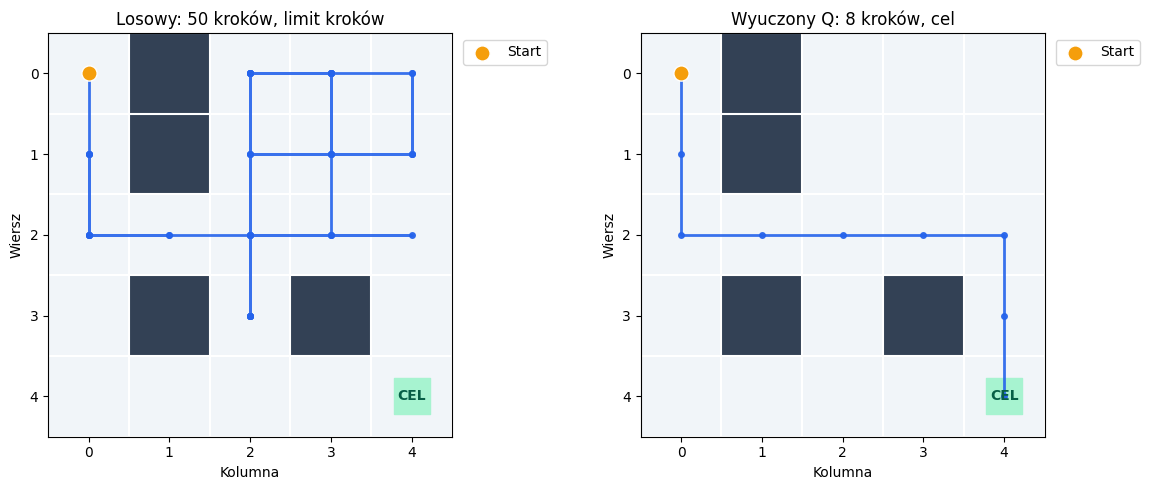

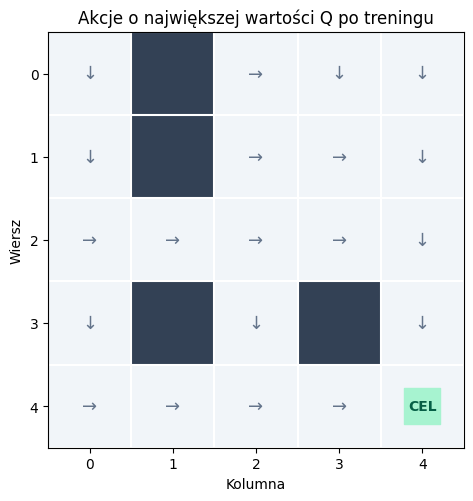

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, label, result in zip(axes, ("Losowy", "Wyuczony Q"),
                             (random_results[0], learned_results[0])):
    outcome = "cel" if result.success else "limit kroków"
    plot_maze(result.path, ax=ax, title=f"{label}: {result.steps} kroków, {outcome}")
fig.tight_layout()
plt.show()

plot_maze(q=q, title="Akcje o największej wartości Q po treningu")
plt.show()

Strzałki oznaczają akcje o największym Q. Jeśli w danym stanie występuje remis,
widać wszystkie najlepsze akcje. Ocena strategii losuje jedną z nich.
Wartość Q nie jest liczbą pozostałych kroków. Uwzględnia nagrody i dyskonto 0,95.

## 7. Zakres dodatkowy: epsilon 0,05 i 0,3

Pozostałe parametry i liczba epizodów pozostają takie same. Każdy wariant startuje
od zerowego Q i dostaje tę samą listę startów treningowych oraz to samo ziarno
generatora akcji. Warianty mogą później wykonać różne liczby losowań, bo wybierają
inne akcje i kończą epizody w innych chwilach.

**Każdą gotową strategię oceniamy z epsilon=0**, także tę uczoną przy epsilon 0,3.
Zmieniamy eksplorację podczas uczenia, nie zasady testu.

| Agent | Sukcesy / próby | Skuteczność | Niepowodzenia | Śr. kroków, sukcesy | Śr. suma nagród |
| --- | --- | --- | --- | --- | --- |
| Losowy | 9/20 | 45% | 11 | 27.22 | -11.22 |
| Q ε=0.05 | 20/20 | 100% | 0 | 4.05 | 9.70 |
| Q ε=0.2 | 20/20 | 100% | 0 | 4.05 | 9.70 |
| Q ε=0.3 | 20/20 | 100% | 0 | 4.05 | 9.70 |

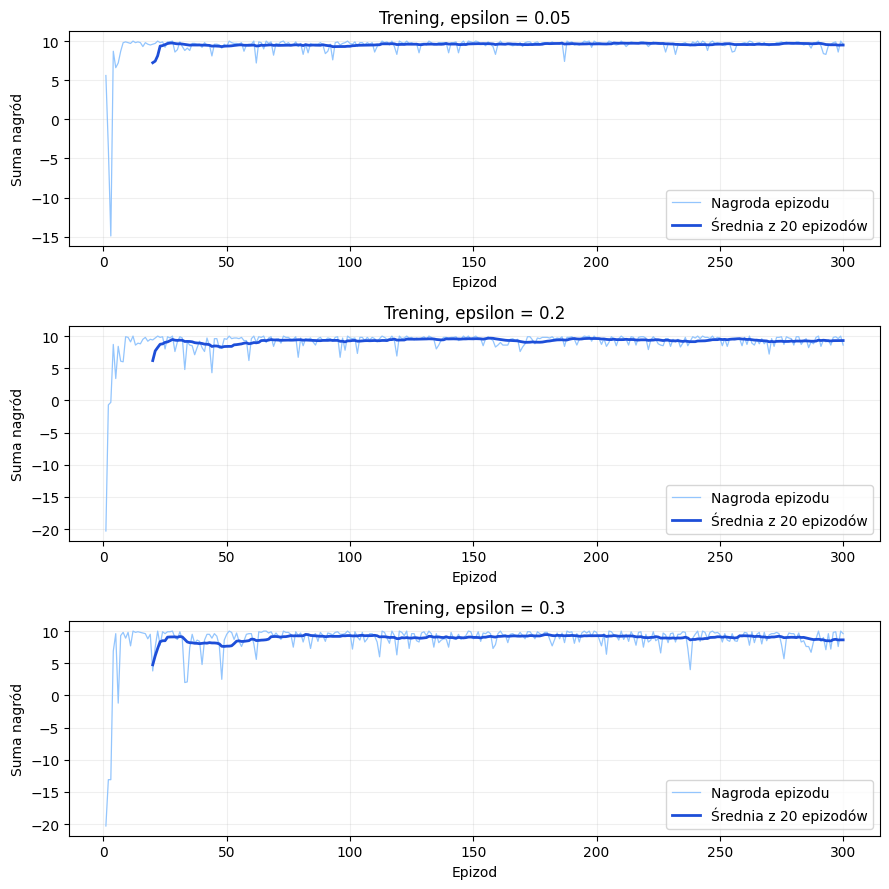

In [16]:
for epsilon in CONFIG["epsilons"]:
    if epsilon not in qs:
        qs[epsilon], histories[epsilon] = train(
            epsilon=epsilon, episodes=CONFIG["episodes"],
            alpha=CONFIG["alpha"], gamma=CONFIG["gamma"],
            max_steps=CONFIG["max_steps"], starts=training_starts,
            start_seed=CONFIG["start_seed"], action_seed=CONFIG["action_seed"],
        )
    label = f"Q ε={epsilon:g}"
    frozen_q = qs[epsilon].copy()
    tests[label] = evaluate(qs[epsilon], starts=TEST_STARTS,
                            seed=CONFIG["eval_seed"], max_steps=CONFIG["max_steps"])
    assert np.array_equal(qs[epsilon], frozen_q)
    summaries[label] = summarize(tests[label])

summary_table(["Losowy", "Q ε=0.05", "Q ε=0.2", "Q ε=0.3"])
plot_rewards({f"Trening, epsilon = {epsilon:g}": histories[epsilon]
              for epsilon in CONFIG["epsilons"]})
plt.show()

## 8. Obserwacje i ograniczenia

Poniższe liczby pochodzą z wykonanych komórek. Po zmianie parametrów uruchom
cały notebook ponownie, żeby wnioski i tablice dotyczyły tego samego przebiegu.

In [17]:
random_metrics = summaries["Losowy"]
q_metrics = summaries["Q ε=0.2"]
first_mean = np.mean([episode.total_reward for episode in history[:30]])
last_mean = np.mean([episode.total_reward for episode in history[-30:]])
optimal_successes = sum(
    result.success and result.steps == shortest_steps(result.start)
    for result in learned_results
)
mean_text = ("brak udanych prób" if q_metrics["mean_steps_success"] is None
             else f'{q_metrics["mean_steps_success"]:.2f} kroku w udanych próbach')
display(Markdown(f"""
* Agent losowy osiągnął cel w **{random_metrics['successes']}/20** prób,
  czyli w {100 * random_metrics['success_rate']:.0f}% prób.
* Q uczone przy epsilon 0,2 osiągnęło cel w **{q_metrics['successes']}/20** prób,
  czyli w {100 * q_metrics['success_rate']:.0f}% prób; {mean_text}.
* W {optimal_successes}/20 startach wyuczona strategia zakończyła próbę
  najkrótszą drogą wskazaną przez BFS.
* Średnia suma nagród z pierwszych 30 epizodów treningowych wyniosła
  {first_mean:.2f}, a z ostatnich 30 epizodów {last_mean:.2f}.
"""))


* Agent losowy osiągnął cel w **9/20** prób,
  czyli w 45% prób.
* Q uczone przy epsilon 0,2 osiągnęło cel w **20/20** prób,
  czyli w 100% prób; 4.05 kroku w udanych próbach.
* W 20/20 startach wyuczona strategia zakończyła próbę
  najkrótszą drogą wskazaną przez BFS.
* Średnia suma nagród z pierwszych 30 epizodów treningowych wyniosła
  7.25, a z ostatnich 30 epizodów 9.34.


Agent podczas treningu może wykonać gorszy ruch, ponieważ eksploracja celowo
sprawdza inne akcje. Pomaga odkrywać drogi, których agent nie wybrałby wyłącznie
na podstawie dotychczasowego Q. Kara za zwykły ruch premiuje krótsze dojście,
a większa kara za niedozwolony ruch zniechęca do prób wejścia w przeszkody.

Test z aktywną eksploracją mierzyłby mieszaninę wyuczonej strategii i losowych
ruchów. Ustawienie epsilon=0 oddziela ten efekt. Wyłączenie aktualizacji Q
zapobiega dalszemu uczeniu podczas porównania.

Wynik dotyczy **tej jednej planszy**. Lista testowa obejmuje jej wszystkie wolne
starty poza celem. Te same stany mogą występować w treningu, więc test ocenia
zamrożoną strategię na znanym środowisku, a nie uogólnianie na nowe labirynty.
Jedna realizacja losowa nie wystarcza do ogólnego rankingu wartości epsilon.
Rzetelniejszy ranking wymagałby wielu ziaren i pokazania rozrzutu wyników.

## 9. Zapis wyników

Poniższe funkcje zapisują tablice Q, konfigurację, starty, tabele CSV, wykresy
oraz sprawozdanie `SPRAWOZDANIE.md`. Korzystają z już policzonych wyników,
bez ponownego treningu. Ten sam kod zapisu jest używany przez repozytorium.
Ziarna i kod pozwalają odtworzyć przebieg. Przed przesłaniem na Teams uzupełnij
dane zespołu.

In [18]:
import csv
import json
import platform
from dataclasses import asdict
from pathlib import Path
import matplotlib


def write_csv(path, rows):
    """Zapisz pełne rekordy; brak średniej lub kroków sukcesu to pusta komórka."""
    rows = list(rows)
    with Path(path).open("w", encoding="utf-8", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)


def format_number(value, digits=2):
    return "brak" if value is None else f"{value:.{digits}f}".replace(".", ",")


def summary_markdown(summaries):
    lines = [
        "| Strategia | Sukcesy | Skuteczność | Porażki | Śr. kroków w sukcesach |",
        "| --- | ---: | ---: | ---: | ---: |",
    ]
    for label, summary in summaries.items():
        lines.append(
            f"| {label} | {summary['successes']}/{summary['episodes']} "
            f"| {format_number(100 * summary['success_rate'], 0)}% "
            f"| {summary['failures']} "
            f"| {format_number(summary['mean_steps_success'])} |")
    return "\n".join(lines)


def paired_markdown(tests):
    lines = [
        "| Próba | Start (wiersz, kolumna) | Losowy: sukces | Losowy: kroki "
        "| Q ε=0,2: sukces | Q: kroki | Najkrótsza droga |",
        "| ---: | --- | --- | ---: | --- | ---: | ---: |",
    ]
    for i, (random_result, learned) in enumerate(
            zip(tests["Losowy"], tests["Q ε=0.2"]), 1):
        random_success = "tak" if random_result.success else "nie, limit"
        learned_success = "tak" if learned.success else "nie, limit"
        lines.append(
            f"| {i} | {learned.start} | {random_success} | {random_result.steps} "
            f"| {learned_success} | {learned.steps} | {shortest_steps(learned.start)} |")
    return "\n".join(lines)


def report_text(experiment):
    """Wnioski i liczby pochodzą z przekazanego wyniku, bez wpisanych metryk."""
    config = experiment["config"]
    tests, summaries = experiment["tests"], experiment["summaries"]
    baseline, learned = summaries["Losowy"], summaries["Q ε=0.2"]
    optimal = sum(result.success and result.steps == shortest_steps(result.start)
                  for result in tests["Q ε=0.2"])
    training_table = [
        "| Epsilon treningowe | Sukcesy w pierwszych 50 | Sukcesy w ostatnich 50 "
        "| Śr. nagroda pierwsze 50 | Śr. nagroda ostatnie 50 |",
        "| ---: | ---: | ---: | ---: | ---: |",
    ]
    for epsilon, history in experiment["histories"].items():
        first, last = summarize(history[:50]), summarize(history[-50:])
        training_table.append(
            f"| {format_number(epsilon)} | {first['successes']}/50 "
            f"| {last['successes']}/50 | {format_number(first['mean_return'])} "
            f"| {format_number(last['mean_return'])} |")
    rates = [summaries[f"Q ε={epsilon:g}"]["success_rate"]
             for epsilon in config["epsilons"]]
    epsilon_conclusion = (
        "Wszystkie warianty uzyskały taki sam odsetek sukcesów w końcowym teście. "
        "Ten test nie wskazał najlepszego epsilon. Różnice widać w historii "
        "treningu i nagrodach zbieranych przy aktywnej eksploracji."
        if len(set(rates)) == 1 else
        "Warianty uzyskały różne odsetki sukcesów w tym przebiegu. "
        "To obserwacja dla podanych ziaren, a nie dowód ogólnej przewagi jednego epsilon."
    )
    return f"""# Warsztat 2. Agent uczący się przejścia labiryntu

## Cel

Nauczyć agenta dojścia do celu na jednej planszy 5 × 5 za pomocą tablicowego
Q-learning. Porównać wyuczoną strategię z agentem losowym i sprawdzić wpływ
epsilon podczas treningu. Wyniki poniżej pochodzą z wykonania dołączonego kodu.

## Środowisko i konfiguracja

Stanem jest pozycja `(wiersz, kolumna)`, liczona od zera. Agent ma cztery akcje:
góra, prawo, dół, lewo. Ściany to `{sorted(WALLS)}`, a cel to `{GOAL}`.
Wszystkie 20 wolnych pól poza celem jest osiągalnymi startami. BFS potwierdza
osiągalność i wyznacza odniesienie dla długości drogi. Nie steruje agentem.

| Parametr | Wartość |
| --- | --- |
| Epizody treningowe na wariant | {config['episodes']} |
| Tempo uczenia alpha | {format_number(config['alpha'])} |
| Dyskonto gamma | {format_number(config['gamma'])} |
| Podstawowe epsilon | {format_number(config['epsilon'])} |
| Zakres dodatkowy | epsilon 0,05 oraz 0,3 |
| Limit kroków | {config['max_steps']} |
| Nagroda za wejście na cel | +10 |
| Nagroda za zwykły ruch | −0,1 |
| Nagroda za ścianę lub wyjście poza planszę | −1, agent pozostaje na miejscu |
| Ziarna: starty / akcje treningowe / ocena | {config['start_seed']} / {config['action_seed']} / {config['eval_seed']} |
| Tablica Q | 5 × 5 × 4, początkowo same zera |

Nagrody są rozłączne. Wejście na cel daje dokładnie +10. Ruch niedozwolony
daje dokładnie −1. Wiersze Q dla ścian i celu nie wymagają uczenia.

## Uczenie i ocena

Z prawdopodobieństwem epsilon agent losuje jedną z czterech akcji, również
niedozwoloną. W pozostałych przypadkach wybiera akcję o największym Q.
Remisy rozstrzyga losowo, także przy epsilon równym zero.

Aktualizacja ma postać `Q[s,a] += alpha * (target - Q[s,a])`, gdzie `target`
wynosi `r` po wejściu na cel, a w pozostałych przejściach
`r + gamma * max(Q[s_next])`. Osiągnięcie celu oznacza `terminated=True`.
Limit 50 kroków oznacza `truncated=True` i nie zeruje wartości przyszłej.
Dotarcie do celu w 50. kroku nadal jest sukcesem.

Każdy trening używa {config['episodes']} losowych dozwolonych startów. Lista jest
losowana wcześniej osobnym generatorem i pozostaje identyczna dla trzech epsilon.
Każdy wariant zaczyna od nowej, zerowej tablicy Q i tego samego ziarna akcji.
Różne przebiegi mogą jednak zużywać losowania inaczej.

Test obejmuje tę samą jawną listę 20 startów, po jednym uruchomieniu z każdego
pola. Agent wyuczony ma epsilon=0, aktualizacja Q jest wyłączona, a kod sprawdza
identyczność Q przed oceną i po niej. Agent losowy losuje spośród wszystkich
czterech akcji. Ocena ma osobny generator, niezależny od treningu.

## Wyniki testowe

{summary_markdown(summaries)}

Agent losowy dotarł do celu w {baseline['successes']} z {baseline['episodes']}
prób. Po treningu podstawowym agent dotarł do celu w
{learned['successes']} z {learned['episodes']} prób. Średnia liczba kroków
w sukcesach wyniosła odpowiednio {format_number(baseline['mean_steps_success'])}
oraz {format_number(learned['mean_steps_success'])}.
Wyuczony agent osiągnął najkrótszą drogę w {optimal}/20 prób.

Skuteczność zawsze uwzględnia wszystkie 20 prób, również nieudane. Średnia
kroków w sukcesach pomija porażki i dotyczy różnych zbiorów udanych prób obu
strategii. Z tego powodu trzeba czytać ją razem ze skutecznością.
W tabeli poniżej porażka ma 50 wykonanych prób ruchu. W CSV pole
`steps_if_success` jest wtedy puste. Każda próba ruchu, również niedozwolona,
zużywa jeden krok.

{paired_markdown(tests)}

## Przebieg uczenia

![Nagrody w treningu podstawowym](results/rewards.png)

Jasna linia pokazuje sumę nagród każdego epizodu, a ciemna średnią z ostatnich
20 epizodów. Średnia pojawia się dopiero przy pełnym oknie 20 obserwacji.
Wykres dotyczy treningu z eksploracją oraz losowymi startami. Nie jest wykresem
oceny zamrożonej strategii.

## Zakres dodatkowy

{chr(10).join(training_table)}

![Porównanie epsilon](results/epsilon_comparison.png)

{epsilon_conclusion}
Same nagrody treningowe zależą również od liczby losowych ruchów i odległości
startu od celu. Nie zastępują końcowego testu przy epsilon=0.

## Przykładowa ścieżka i strategia

![Losowy agent i wyuczona strategia ze wspólnego startu](results/paths.png)

![Zachłanne akcje z wyuczonej tablicy Q](results/policy.png)

Ścieżki dotyczą startu `(0, 0)`. Liczba kroków uwzględnia także próby,
które pozostawiły agenta na miejscu, choć takie ruchy nakładają się na rysunku.
Mapa strategii pokazuje wszystkie akcje z maksymalnym Q, jeśli wystąpił remis.

## Odpowiedzi i ograniczenia

Podczas treningu agent może świadomie wylosować gorszy ruch. Eksploracja pozwala
odwiedzać mniej znane pary stan–akcja i poprawiać ich oszacowania, kosztem
bieżącej nagrody. Na początku wartości Q także są niedokładne, więc nawet
wybór zachłanny nie musi być dobry.

Test z aktywną eksploracją mierzyłby połączenie wyuczonej strategii i losowych
odstępstw od niej. Dlatego podczas oceny epsilon wynosi zero. Losowe
rozstrzyganie remisów pozostaje częścią zdefiniowanej strategii zachłannej.

Wynik dotyczy jednej planszy. Agent zapamiętał wartości pozycji na tej planszy,
nie nauczył się rozwiązywania dowolnego labiryntu. Starty testowe należą do tego
samego środowiska co trening. Wyniki agenta losowego i porównanie epsilon
pochodzą z jednego zestawu ziaren, bez przedziałów niepewności.
Do szerszych wniosków potrzeba wielu niezależnych treningów oraz innych plansz.

## Odtworzenie i pliki

Polecenie `python run_experiments.py` odtwarza eksperymenty i to sprawozdanie.
Notebook zawiera cały kod i zapisane wyniki. Tablicę podstawową można odczytać
przez `np.load("results/q_table.npy", allow_pickle=False)`.

- `results/config.json`: parametry, plansza, starty treningowe i testowe, wersje środowiska.
- `results/q_table.npy` i `results/q_tables.npz`: tablice podstawowa i trzech wariantów.
- `results/q_values.csv`: wszystkie wartości podstawowej Q w czytelnej tabeli.
- `results/training_history.csv`: wszystkie 900 epizodów treningowych.
- `results/test_results.csv`: wszystkie 80 prób, wraz z porażkami i flagami zakończenia.
- `results/test_comparison.csv`: zestawienie 20 wspólnych startów.
- `results/summary.csv`: metryki zbiorcze.
- `results/test_paths.json`: pełne ścieżki i akcje testowe.

Testy uruchamia się przez `python -m unittest discover -s tests -v`.
"""


def save_artifacts(experiment, output_dir="results"):
    """Zapisz wyliczone wyniki; nie uruchamiaj ponownie treningu ani oceny."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    config = dict(experiment["config"])
    config.update({
        "grid": GRID.tolist(), "goal": list(GOAL),
        "walls": [list(wall) for wall in sorted(WALLS)],
        "actions": list(ACTION_NAMES),
        "q_shape": [SIZE, SIZE, 4],
        "test_starts": [list(start) for start in TEST_STARTS],
        "training_starts": [list(start) for start in experiment["training_starts"]],
        "rewards": {"goal": 10.0, "move": -0.1, "invalid": -1.0},
        "evaluation_epsilon": 0.0, "evaluation_learning": False,
        "versions": {"python": platform.python_version(), "numpy": np.__version__,
                     "matplotlib": matplotlib.__version__},
    })
    (output_dir / "config.json").write_text(
        json.dumps(config, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    q = experiment["qs"][0.2]
    np.save(output_dir / "q_table.npy", q, allow_pickle=False)
    np.savez(output_dir / "q_tables.npz",
             **{f"epsilon_{str(epsilon).replace('.', '_')}": table
                for epsilon, table in experiment["qs"].items()})

    q_rows = []
    for row in range(SIZE):
        for col in range(SIZE):
            for action, name in enumerate(ACTION_NAMES):
                state = (row, col)
                kind = "wall" if state in WALLS else "goal" if state == GOAL else "free"
                q_rows.append({"row": row, "col": col, "cell_type": kind,
                               "action": name, "q": q[row, col, action]})
    write_csv(output_dir / "q_values.csv", q_rows)

    training_rows = []
    for epsilon, history in experiment["histories"].items():
        for episode, result in enumerate(history, 1):
            training_rows.append({"epsilon": epsilon, "episode": episode,
                                  "start_row": result.start[0],
                                  "start_col": result.start[1],
                                  "success": result.success, "steps": result.steps,
                                  "total_reward": round(result.total_reward, 10),
                                  "terminated": result.terminated,
                                  "truncated": result.truncated})
    write_csv(output_dir / "training_history.csv", training_rows)

    tests = experiment["tests"]
    write_csv(output_dir / "test_results.csv",
              ({"strategy": label, **row} for label, results in tests.items()
               for row in evaluation_rows(results)))
    write_csv(output_dir / "summary.csv",
              ({"strategy": label, **summary}
               for label, summary in experiment["summaries"].items()))
    write_csv(output_dir / "test_comparison.csv", (
        {"trial": i, "start_row": learned.start[0], "start_col": learned.start[1],
         "random_success": random_result.success, "random_steps": random_result.steps,
         "random_steps_if_success": random_result.steps if random_result.success else None,
         "learned_success": learned.success, "learned_steps": learned.steps,
         "learned_steps_if_success": learned.steps if learned.success else None,
         "shortest_steps": shortest_steps(learned.start)}
        for i, (random_result, learned) in enumerate(
            zip(tests["Losowy"], tests["Q ε=0.2"]), 1)))
    (output_dir / "test_paths.json").write_text(json.dumps(
        {label: [asdict(result) for result in results] for label, results in tests.items()},
        ensure_ascii=False, indent=2) + "\n", encoding="utf-8")

    fig, _ = plot_rewards({"Q-learning, epsilon = 0,2": experiment["histories"][0.2]})
    fig.savefig(output_dir / "rewards.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    fig, _ = plot_rewards({f"Epsilon = {format_number(epsilon)}": history
                           for epsilon, history in experiment["histories"].items()})
    fig.savefig(output_dir / "epsilon_comparison.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5), layout="constrained")
    for ax, label in zip(axes, ["Losowy", "Q ε=0.2"]):
        result = tests[label][0]
        status = "cel" if result.success else "limit"
        plot_maze(path=result.path, ax=ax,
                  title=f"{label}: {result.steps} kroków, {status}")
    fig.savefig(output_dir / "paths.png", dpi=150, bbox_inches="tight")
    plt.close(fig)
    fig, _ = plot_maze(q=q, title="Wyuczona strategia, epsilon testowe = 0")
    fig.savefig(output_dir / "policy.png", dpi=150, bbox_inches="tight")
    plt.close(fig)

    report_path = output_dir.parent / "SPRAWOZDANIE.md"
    text = report_text(experiment).replace(
        "](results/", f"]({output_dir.name}/")
    report_path.write_text(text, encoding="utf-8")
    return report_path

In [19]:
labels = ["Losowy"] + [f"Q ε={epsilon:g}" for epsilon in CONFIG["epsilons"]]
experiment = {
    "config": dict(CONFIG),
    "training_starts": training_starts,
    "qs": {epsilon: qs[epsilon] for epsilon in CONFIG["epsilons"]},
    "histories": {epsilon: histories[epsilon] for epsilon in CONFIG["epsilons"]},
    "tests": {label: tests[label] for label in labels},
    "summaries": {label: summaries[label] for label in labels},
}
report_path = save_artifacts(experiment, output_dir="results")
print("Zapisano sprawozdanie:", report_path)
print("Tablica podstawowa:", Path("results/q_table.npy"))
print("Konfiguracja, CSV i wykresy:", Path("results"))

Zapisano sprawozdanie: SPRAWOZDANIE.md
Tablica podstawowa: results/q_table.npy
Konfiguracja, CSV i wykresy: results


### Demo zespołu, 5–6 minut

1. Pokaż planszę i przejście agenta losowego.
2. Pokaż ścieżkę wyuczonej strategii i tabelę skuteczności z 20 prób.
3. Wyjaśnij rolę nagród, eksploracji i epsilon=0 podczas oceny.
4. Wskaż rozdzielenie celu od limitu 50 kroków oraz ograniczenie do jednej planszy.

Do oddania: notebook z wynikami, kod, tablica Q lub możliwość jej odtworzenia
oraz sprawozdanie. W repozytorium gotowe sprawozdanie generuje skrypt eksperymentu.